# 19장 · LCEL 체인과 출력 파서

LCEL의 파이프 연산자(|)는 앞 구성 요소의 출력을 다음 구성 요소의 입력으로 넘깁니다. 프롬프트, 모델, 출력 파서가 각각 주고받는 값이 다릅니다.

도서관 안내 문장과 질문을 넣으면 체인은 무엇을 모델에 보낼까요? 프롬프트를 완성한 순간의 값부터 읽은 다음 모델 메시지가 화면에 표시할 문자열이 되기까지 따라가 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain-core 1.6.12입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## ChatPromptTemplate의 입력 변수

템플릿은 비어 있는 칸에 이번 자료를 넣어 요청을 만드는 틀입니다. context에는 근거를, question에는 묻는 문장을 넣습니다. 먼저 표준 파이썬으로 그 두 값을 확인합니다.


### 셀 01 · 프롬프트 입력 딕셔너리

context와 question이 다른 역할을 한다는 점을 보세요.


In [1]:
inputs = {"context": "수업용 가상 도서관의 대출 기간은 14일이다.", "question": "대출은 며칠인가요?"}
print(inputs["context"])

수업용 가상 도서관의 대출 기간은 14일이다.


대출 기간을 뒷받침하는 문장입니다. 딕셔너리에서 빈칸과 같은 이름의 값을 찾아야 하므로 context를 contents로 적으면 약속한 칸을 찾지 못합니다.


### 과제 02 · context와 question 치환

파이썬 문자열 format에 inputs를 전달해 근거와 질문이 각각 들어간 문장을 출력하세요. 이 셀은 LCEL을 쓰기 전의 작은 연습입니다.


In [2]:
# {context}와 {question}을 실제 값으로 바꾸세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>template = &quot;근거: {context}\n질문: {question}&quot;
print(template.format(**inputs))</code></pre>
<p>실행 결과</p><pre><code>근거: 수업용 가상 도서관의 대출 기간은 14일이다.
질문: 대출은 며칠인가요?</code></pre>
<p>첫 줄에는 자료가, 둘째 줄에는 질문이 남습니다. 템플릿 자체를 화면에 찍으면 중괄호 안의 이름이 그대로 보입니다.</p>
</details>


## 파이프 연산자와 StrOutputParser, invoke()

LangChain Expression Language(LCEL)의 |는 앞 구성 요소가 돌려준 값을 다음 요소에 건넵니다. 수업 환경에 langchain-core가 설치되어 있으면 아래 셀로 실제 체인을 만듭니다. FakeListChatModel은 고정 답변을 내는 수업용 모델입니다.

**LCEL의 연속 변환**　카드가 첫 필터를 통과한 뒤 두 번째 필터로 들어갑니다. 코드에서 각 단계가 반환하는 메시지와 문자열을 차례로 확인하세요.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter19/index.html#concept-clip)


### 셀 03 · to_messages()의 content

모델을 부르기 전에 ChatPromptTemplate이 만든 값에서 질문을 먼저 꺼내 봅니다.


In [3]:
from importlib.util import find_spec
has_lcel = find_spec("langchain_core") is not None
if has_lcel:
    from langchain_core.prompts import ChatPromptTemplate
    from langchain_core.language_models.fake_chat_models import FakeListChatModel
    from langchain_core.output_parsers import StrOutputParser
    prompt = ChatPromptTemplate.from_messages([("system", "주어진 사실만 사용하세요. 사실: {context}"),
                                               ("human", "{question}")])
    print(prompt.invoke(inputs).to_messages()[-1].content)
else:
    print("langchain-core가 설치된 수업 커널에서 메시지 변환을 실행하세요.")

대출은 며칠인가요?


마지막 메시지에는 ‘대출은 며칠인가요?’라는 질문이 들어 있습니다. prompt의 반환값 안에는 system 메시지도 들어 있습니다. 둘을 합친 메시지 묶음이 모델 입력입니다.


### 셀 04 · StrOutputParser와 invoke()

고정 모델 뒤에 문자열 파서를 이어 실제 LCEL 경로를 실행합니다.

모델 뒤에서 멈추면 답은 메시지 객체에 담겨 있습니다. 뒤에 StrOutputParser를 연결하면 invoke의 반환값으로 본문 문자열을 얻습니다. 이 노트북의 실행 기록은 langchain-core 1.6.12 기준이고 더 읽기의 1.8.0은 별도 기록입니다.


In [4]:
if has_lcel:
    model = FakeListChatModel(responses=["가상 도서관의 대출 기간은 14일입니다."])
    chain = prompt | model | StrOutputParser()
    print(chain.invoke(inputs))
else:
    print("LCEL 체인을 실행하려면 langchain-core가 필요합니다.")

가상 도서관의 대출 기간은 14일입니다.


체인이 실행되면 ‘가상 도서관의 대출 기간은 14일입니다.’라는 문자열이 나옵니다. 파서는 모델이 만든 메시지에서 글을 꺼내고, 지정한 고정 모델은 원문의 사실 여부를 검증하지 않습니다.


## stream()과 출력 조각 결합

invoke는 한 번에 결과를 받고 stream은 차례로 오는 조각을 읽습니다. 조각 하나의 경계는 문장이나 단어의 경계와 같지 않을 수 있습니다.

<!-- lesson-visual detail-stream -->
**두 출력 조각이 한 문자열이 되는 과정**

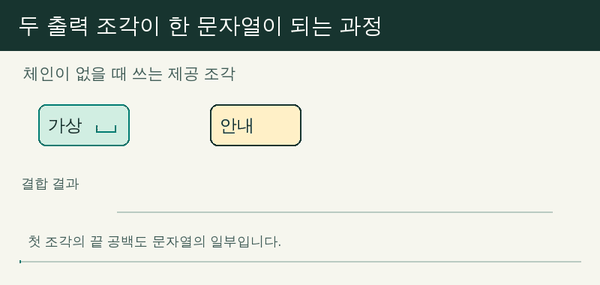

제공된 두 조각 "가상 "과 "안내"는 도착 순서로 이어집니다. 빈 문자열로 join해도 첫 조각 끝의 공백이 남아서 "가상 안내"가 됩니다.
<!-- /lesson-visual detail-stream -->


### 과제 05 · 스트림 문자열 결합

LCEL 환경에서는 chain.stream의 조각을 이어 전체 답을 출력하세요. 라이브러리가 없는 경우 제공 조각으로 결합 연산만 연습합니다.


In [5]:
pieces = ["가상 ", "안내"]
# 수업 환경에 맞게 출력 조각을 이어 보세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>if has_lcel:
    pieces = chain.stream(inputs)
else:
    pieces = [&quot;가상 &quot;, &quot;안내&quot;]
print(&quot;&quot;.join(pieces))</code></pre>
<p>실행 결과</p><pre><code>가상 도서관의 대출 기간은 14일입니다.</code></pre>
<p>실제 체인을 쓴 경우 앞의 invoke와 같은 고정 문장이 됩니다. 제공 조각만 썼다면 ‘가상 안내’가 결과입니다. 고정 모델의 조각 수를 실제 API의 토큰 수로 해석할 수는 없습니다.</p>
</details>


## 돌아보기

입력 사전, 모델에 보낼 메시지 묶음, 마지막 문자열을 순서대로 가리켜 보세요. 다음 장에서는 context를 손으로 쓰는 대신 어느 문서에서 가져올지 정합니다.
